In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel('Data/Online Retail.xlsx')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
before_rows = len(df)
before_invoices = df['InvoiceNo'].nunique()
before_customers = df['CustomerID'].nunique()

print("Jumlah baris:", before_rows)
print("Jumlah invoice:", before_invoices)
print("Jumlah pelanggan:", before_customers)

Jumlah baris: 541909
Jumlah invoice: 25900
Jumlah pelanggan: 4372


In [8]:
df_clean = df.copy()

# Menghapus Description dan CustomerID kosong
df_clean = df_clean.dropna(subset=['Description', 'CustomerID'])

# Menghapus transaksi yang dibatalkan
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Menghapus Quantity <= 0
df_clean = df_clean[df_clean['Quantity'] > 0]

# Memastikan InvoiceDate berbentuk datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Menghapus tanggal atau invoice yang tidak valid
df_clean = df_clean.dropna(subset=['InvoiceDate', 'InvoiceNo'])

In [9]:
comparison = pd.DataFrame({
    'Sebelum Cleaning': [
        before_rows,
        before_invoices,
        before_customers
    ],
    'Sesudah Cleaning': [
        len(df_clean),
        df_clean['InvoiceNo'].nunique(),
        df_clean['CustomerID'].nunique()
    ]
}, index=['Jumlah Baris', 'Jumlah Invoice', 'Jumlah Pelanggan'])

comparison

,Sebelum Cleaning,Sesudah Cleaning
Jumlah Baris,541909,397924
Jumlah Invoice,25900,18536
Jumlah Pelanggan,4372,4339


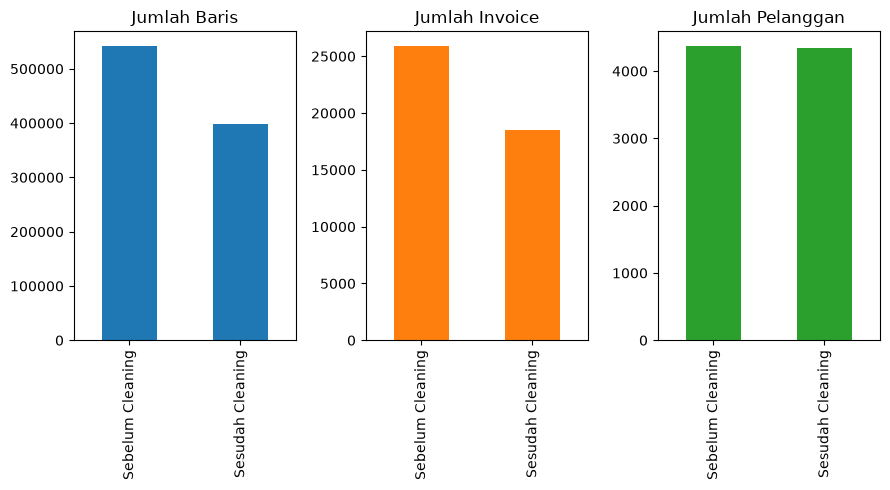

In [10]:
comparison.T.plot(
    kind='bar',
    figsize=(9, 5),
    subplots=True,
    layout=(1, 3),
    legend=False,
    title=['Jumlah Baris', 'Jumlah Invoice', 'Jumlah Pelanggan']
)

plt.tight_layout()
plt.show()

In [11]:
df_clean = df_clean.sort_values(
    by=['CustomerID', 'InvoiceDate', 'InvoiceNo']
).reset_index(drop=True)

df_clean[['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Description']].head(10)

,CustomerID,InvoiceNo,InvoiceDate,Description
0,12346.0,541431,2011-01-18 10:01:00,MEDIUM CERAMIC TOP STORAGE JAR
1,12347.0,537626,2010-12-07 14:57:00,BLACK CANDELABRA T-LIGHT HOLDER
2,12347.0,537626,2010-12-07 14:57:00,AIRLINE BAG VINTAGE JET SET BROWN
3,12347.0,537626,2010-12-07 14:57:00,COLOUR GLASS. STAR T-LIGHT HOLDER
4,12347.0,537626,2010-12-07 14:57:00,MINI PAINT SET VINTAGE
5,12347.0,537626,2010-12-07 14:57:00,CLEAR DRAWER KNOB ACRYLIC EDWARDIAN
6,12347.0,537626,2010-12-07 14:57:00,PINK DRAWER KNOB ACRYLIC EDWARDIAN
7,12347.0,537626,2010-12-07 14:57:00,GREEN DRAWER KNOB ACRYLIC EDWARDIAN
8,12347.0,537626,2010-12-07 14:57:00,RED DRAWER KNOB ACRYLIC EDWARDIAN
9,12347.0,537626,2010-12-07 14:57:00,PURPLE DRAWERKNOB ACRYLIC EDWARDIAN


In [12]:
transactions = (
    df_clean.groupby(
        ['CustomerID', 'InvoiceNo', 'InvoiceDate'],
        sort=False
    )['Description']
    .apply(lambda x: sorted(set(x)))
    .reset_index(name='Itemset')
)

transactions.head(10)

,CustomerID,InvoiceNo,InvoiceDate,Itemset
0,12346.0,541431,2011-01-18 10:01:00,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347.0,537626,2010-12-07 14:57:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VIN..."
2,12347.0,542237,2011-01-26 14:30:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIR..."
3,12347.0,549222,2011-04-07 10:43:00,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STI..."
4,12347.0,556201,2011-06-09 13:01:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VIN..."
5,12347.0,562032,2011-08-02 08:48:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIR..."
6,12347.0,573511,2011-10-31 12:25:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIR..."
7,12347.0,581180,2011-12-07 15:52:00,"[BICYCLE PUNCTURE REPAIR KIT , BOOM BOX SPEAKE..."
8,12348.0,539318,2010-12-16 19:09:00,"[60 CAKE CASES DOLLY GIRL DESIGN, 60 CAKE CASE..."
9,12348.0,541998,2011-01-25 10:42:00,"[MULTI HEARTS STICKERS, PACK OF 12 BLUE PAISL..."


In [13]:
customer_sequences = (
    transactions.sort_values(
        ['CustomerID', 'InvoiceDate', 'InvoiceNo']
    )
    .groupby('CustomerID')['Itemset']
    .apply(list)
)

customer_sequences.head()

CustomerID
12346.0                   [[MEDIUM CERAMIC TOP STORAGE JAR]]
12347.0    [[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VI...
12348.0    [[60 CAKE CASES DOLLY GIRL DESIGN, 60 CAKE CAS...
12349.0    [[16 PIECE CUTLERY SET PANTRY DESIGN, 20 DOLLY...
12350.0    [[4 TRADITIONAL SPINNING TOPS, BATHROOM METAL ...
Name: Itemset, dtype: object

In [14]:
sequences = customer_sequences.tolist()

print("Jumlah sequence:", len(sequences))
print("Contoh sequence pelanggan pertama:")
print(sequences[0])

Jumlah sequence: 4339
Contoh sequence pelanggan pertama:
[['MEDIUM CERAMIC TOP STORAGE JAR']]


count    4339.000000
mean        4.278866
std         7.727621
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       211.000000
Name: Itemset, dtype: float64


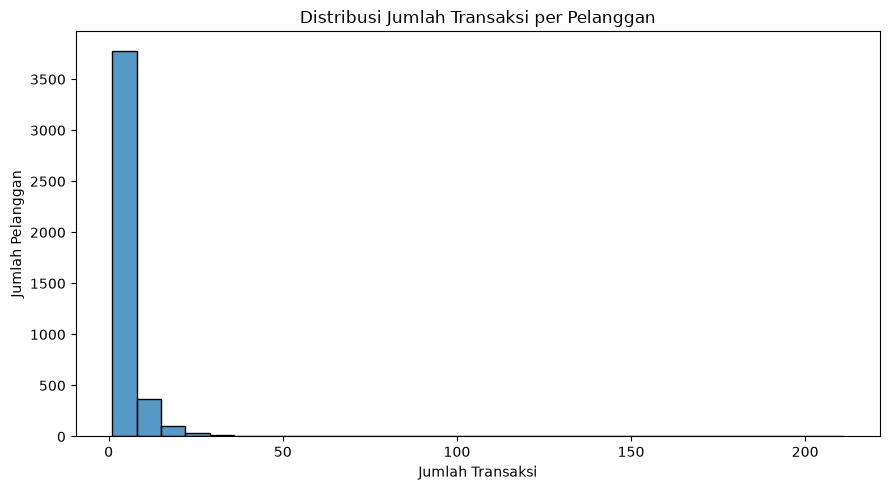

In [15]:
sequence_lengths = customer_sequences.apply(len)

print(sequence_lengths.describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    sequence_lengths,
    bins=30
)

plt.title('Distribusi Jumlah Transaksi per Pelanggan')
plt.xlabel('Jumlah Transaksi')
plt.ylabel('Jumlah Pelanggan')
plt.tight_layout()
plt.show()

In [16]:
unique_items = sorted(df_clean['Description'].unique())

item_to_id = {
    item: idx + 1
    for idx, item in enumerate(unique_items)
}

id_to_item = {
    idx: item
    for item, idx in item_to_id.items()
}

print("Jumlah item unik:", len(item_to_id))

Jumlah item unik: 3877


In [17]:
spmf_sequences = []

for sequence in sequences:
    encoded = []

    for itemset in sequence:
        encoded.extend(
            sorted(item_to_id[item] for item in itemset)
        )
        encoded.append(-1)

    encoded.append(-2)
    spmf_sequences.append(encoded)

print(spmf_sequences[0][:50])

[1993, -1, -2]


In [18]:
with open('retail_sequences.txt', 'w', encoding='utf-8') as f:
    for sequence in spmf_sequences:
        f.write(' '.join(map(str, sequence)) + '\n')

print("File retail_sequences.txt berhasil dibuat")

File retail_sequences.txt berhasil dibuat


In [ ]:
from spmf import Spmf
from pathlib import Path

project_dir = Path.cwd()

spmf = Spmf(
    "PrefixSpan",
    input_filename=str(project_dir / "retail_sequences.txt"),
    output_filename=str(project_dir / "prefixspan_output.txt"),
    arguments=[0.01],
    spmf_bin_location_dir=str(project_dir)
)

spmf.run()

In [35]:
patterns = spmf.to_pandas_dataframe()

display(patterns.head(10))

print("Jumlah pola ditemukan:", len(patterns))

,pattern,sup
0,[2],106
1,[2 96],65
2,[2 100],51
3,[3],100
4,[3 993],55
5,[3 3311],79
6,[3 3317],48
7,[4],58
8,[8],82
9,[8 2755],52


Jumlah pola ditemukan: 141518


In [36]:
patterns = []

with open("prefixspan_output.txt", "r", encoding="utf-8") as f:
    for line in f:
        if "#SUP:" not in line:
            continue

        pattern_text, support_text = line.split("#SUP:")

        itemsets = []
        current_itemset = []

        for token in pattern_text.split():
            item_id = int(token)

            if item_id == -1:
                if current_itemset:
                    itemsets.append(current_itemset)
                    current_itemset = []
            elif item_id > 0:
                current_itemset.append(id_to_item[item_id])

        patterns.append({
            "pattern": itemsets,
            "support_count": int(support_text.strip().split()[0])
        })

patterns_df = pd.DataFrame(patterns)

print("Jumlah pola ditemukan:", len(patterns_df))
patterns_df.head()

Jumlah pola ditemukan: 141518


,pattern,support_count
0,[[ 50'S CHRISTMAS GIFT BAG LARGE]],106
1,"[[ 50'S CHRISTMAS GIFT BAG LARGE, 50'S CHRISTM...",65
2,"[[ 50'S CHRISTMAS GIFT BAG LARGE, 6 GIFT TAGS ...",51
3,[[ DOLLY GIRL BEAKER]],100
4,"[[ DOLLY GIRL BEAKER, DOLLY GIRL LUNCH BOX]]",55


In [37]:
n_customers = len(sequences)

patterns_df["support"] = (
    patterns_df["support_count"] / n_customers
)

patterns_df["n_itemsets"] = patterns_df["pattern"].apply(len)

patterns_df.head()

,pattern,support_count,support,n_itemsets
0,[[ 50'S CHRISTMAS GIFT BAG LARGE]],106,0.024430,1
1,"[[ 50'S CHRISTMAS GIFT BAG LARGE, 50'S CHRISTM...",65,0.014980,1
2,"[[ 50'S CHRISTMAS GIFT BAG LARGE, 6 GIFT TAGS ...",51,0.011754,1
3,[[ DOLLY GIRL BEAKER]],100,0.023047,1
4,"[[ DOLLY GIRL BEAKER, DOLLY GIRL LUNCH BOX]]",55,0.012676,1


In [38]:
sequential_patterns = patterns_df[
    patterns_df["n_itemsets"] >= 2
].copy()

sequential_patterns = sequential_patterns.sort_values(
    "support",
    ascending=False
)

print("Jumlah pola berurutan:", len(sequential_patterns))

sequential_patterns.head(10)

Jumlah pola berurutan: 130584


,pattern,support_count,support,n_itemsets
140015,"[[WHITE HANGING HEART T-LIGHT HOLDER], [WHITE ...",405,0.093339,2
131993,"[[REGENCY CAKESTAND 3 TIER], [REGENCY CAKESTAN...",330,0.076054,2
34298,"[[JUMBO BAG RED RETROSPOT], [JUMBO BAG RED RET...",312,0.071906,2
3337,"[[ASSORTED COLOUR BIRD ORNAMENT], [ASSORTED CO...",291,0.067066,2
127126,"[[PARTY BUNTING], [PARTY BUNTING]]",280,0.064531,2
107032,"[[LUNCH BAG RED RETROSPOT], [LUNCH BAG RED RET...",276,0.063609,2
58687,"[[LUNCH BAG BLACK SKULL.], [LUNCH BAG BLACK ...",229,0.052777,2
134677,"[[SET OF 3 CAKE TINS PANTRY DESIGN ], [SET OF ...",225,0.051855,2
140249,"[[WHITE HANGING HEART T-LIGHT HOLDER], [WHITE ...",222,0.051164,3
101818,"[[LUNCH BAG RED RETROSPOT], [LUNCH BAG BLACK ...",212,0.048859,2


In [39]:
support_lookup = {
    tuple(tuple(itemset) for itemset in row["pattern"]): row["support_count"]
    for _, row in patterns_df.iterrows()
}

def calculate_confidence(pattern, support_count):
    prefix = tuple(
        tuple(itemset)
        for itemset in pattern[:-1]
    )

    prefix_support = support_lookup.get(prefix, 0)

    if prefix_support == 0:
        return np.nan

    return support_count / prefix_support

sequential_patterns["confidence"] = sequential_patterns.apply(
    lambda row: calculate_confidence(
        row["pattern"],
        row["support_count"]
    ),
    axis=1
)

sequential_patterns.head(10)

,pattern,support_count,support,n_itemsets,confidence
140015,"[[WHITE HANGING HEART T-LIGHT HOLDER], [WHITE ...",405,0.093339,2,0.473131
131993,"[[REGENCY CAKESTAND 3 TIER], [REGENCY CAKESTAN...",330,0.076054,2,0.374574
34298,"[[JUMBO BAG RED RETROSPOT], [JUMBO BAG RED RET...",312,0.071906,2,0.491339
3337,"[[ASSORTED COLOUR BIRD ORNAMENT], [ASSORTED CO...",291,0.067066,2,0.429204
127126,"[[PARTY BUNTING], [PARTY BUNTING]]",280,0.064531,2,0.395480
107032,"[[LUNCH BAG RED RETROSPOT], [LUNCH BAG RED RET...",276,0.063609,2,0.518797
58687,"[[LUNCH BAG BLACK SKULL.], [LUNCH BAG BLACK ...",229,0.052777,2,0.500000
134677,"[[SET OF 3 CAKE TINS PANTRY DESIGN ], [SET OF ...",225,0.051855,2,0.351562
140249,"[[WHITE HANGING HEART T-LIGHT HOLDER], [WHITE ...",222,0.051164,3,0.548148
101818,"[[LUNCH BAG RED RETROSPOT], [LUNCH BAG BLACK ...",212,0.048859,2,0.398496


In [40]:
def format_pattern(pattern):
    return " → ".join(
        "{" + ", ".join(itemset) + "}"
        for itemset in pattern
    )

sequential_patterns["pattern_name"] = (
    sequential_patterns["pattern"].apply(format_pattern)
)

result = sequential_patterns[
    ["pattern_name", "support_count", "support", "confidence"]
].copy()

result.head(10)

,pattern_name,support_count,support,confidence
140015,{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE ...,405,0.093339,0.473131
131993,{REGENCY CAKESTAND 3 TIER} → {REGENCY CAKESTAN...,330,0.076054,0.374574
34298,{JUMBO BAG RED RETROSPOT} → {JUMBO BAG RED RET...,312,0.071906,0.491339
3337,{ASSORTED COLOUR BIRD ORNAMENT} → {ASSORTED CO...,291,0.067066,0.429204
127126,{PARTY BUNTING} → {PARTY BUNTING},280,0.064531,0.395480
107032,{LUNCH BAG RED RETROSPOT} → {LUNCH BAG RED RET...,276,0.063609,0.518797
58687,{LUNCH BAG BLACK SKULL.} → {LUNCH BAG BLACK ...,229,0.052777,0.500000
134677,{SET OF 3 CAKE TINS PANTRY DESIGN } → {SET OF ...,225,0.051855,0.351562
140249,{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE ...,222,0.051164,0.548148
101818,{LUNCH BAG RED RETROSPOT} → {LUNCH BAG BLACK ...,212,0.048859,0.398496


In [41]:
top3 = result.nlargest(3, "support").copy()

top3

,pattern_name,support_count,support,confidence
140015,{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE ...,405,0.093339,0.473131
131993,{REGENCY CAKESTAND 3 TIER} → {REGENCY CAKESTAN...,330,0.076054,0.374574
34298,{JUMBO BAG RED RETROSPOT} → {JUMBO BAG RED RET...,312,0.071906,0.491339


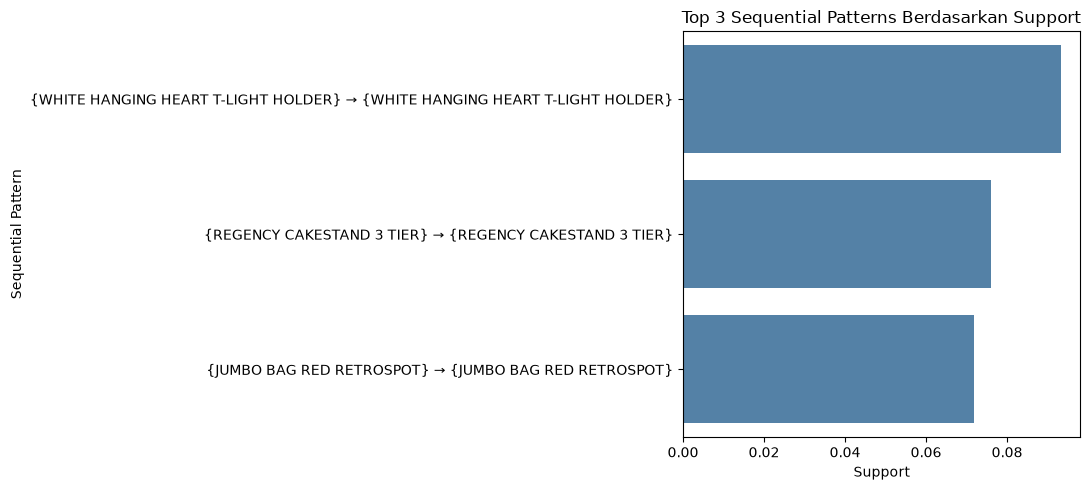

In [42]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=top3,
    x="support",
    y="pattern_name",
    color="steelblue"
)

plt.title("Top 3 Sequential Patterns Berdasarkan Support")
plt.xlabel("Support")
plt.ylabel("Sequential Pattern")
plt.tight_layout()
plt.show()

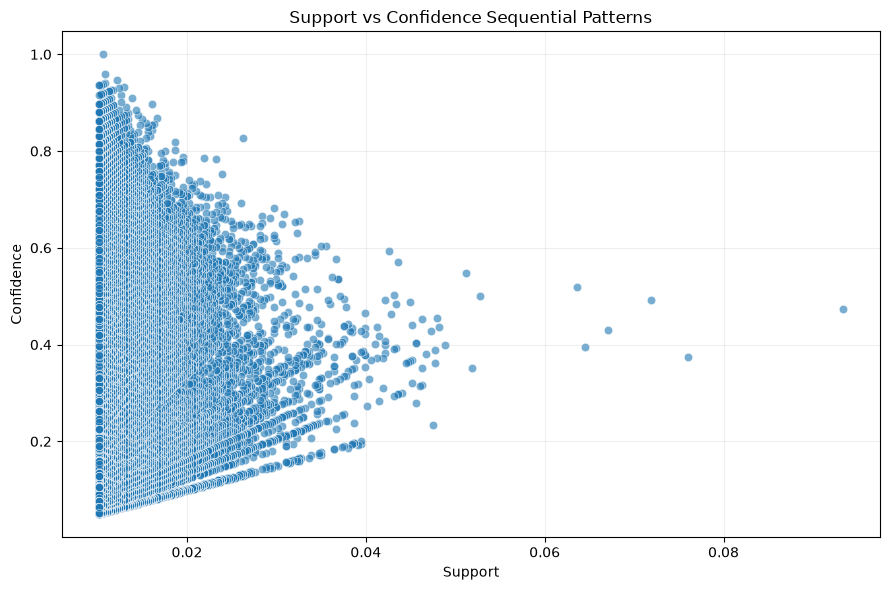

In [43]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=result,
    x="support",
    y="confidence",
    alpha=0.6
)

plt.title("Support vs Confidence Sequential Patterns")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()